<a href="https://colab.research.google.com/github/PARODBE/Clase/blob/main/eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import scipy

pd.set_option("display.max_columns", 10)

df = pd.read_json("/content/drive/MyDrive/Colab Notebooks/employees.json")

In [ ]:
df

,emp_no,edad,antiguedad,genero,rol,salario,departamento
0,10001,49,16,M,Senior Engineer,88958,Development
1,10002,38,17,F,Staff,72527,Sales
2,10003,43,16,M,Senior Engineer,43311,Production
3,10004,48,16,M,Senior Engineer,74057,Production
4,10005,47,13,M,Senior Staff,94692,Human Resources
...,...,...,...,...,...,...,...
797,10995,39,5,F,Senior Staff,48215,Marketing
798,10996,47,12,F,Senior Staff,65811,Sales
799,10997,43,8,F,Technique Leader,42260,Production
800,10998,46,10,M,Staff,68449,Sales


DESCRIPCIÓN

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 802 entries, 0 to 801
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   emp_no        802 non-null    int64 
 1   edad          802 non-null    int64 
 2   antiguedad    802 non-null    int64 
 3   genero        802 non-null    object
 4   rol           802 non-null    object
 5   salario       802 non-null    int64 
 6   departamento  802 non-null    object
dtypes: int64(4), object(3)
memory usage: 50.1+ KB


In [ ]:
df["genero"] = df["genero"].astype("category")
df["departamento"] = df["departamento"].astype("category")
df["rol"] = df["rol"].astype("category")

In [ ]:
df.drop(columns="emp_no").describe(include="all")

,edad,antiguedad,genero,rol,salario,departamento
count,802.000000,802.000000,802,802,802.000000,802
unique,NaN,NaN,2,6,NaN,9
top,NaN,NaN,M,Senior Engineer,NaN,Development
freq,NaN,NaN,482,282,NaN,203
mean,43.850374,12.301746,NaN,NaN,71792.773067,NaN
std,3.706802,3.420029,NaN,NaN,17180.025604,NaN
min,37.000000,3.000000,NaN,NaN,40063.000000,NaN
25%,41.000000,10.000000,NaN,NaN,58612.750000,NaN
50%,44.000000,13.000000,NaN,NaN,69734.000000,NaN
75%,47.000000,15.000000,NaN,NaN,83199.250000,NaN


OUTLIERS

In [ ]:
iqr_salario = scipy.stats.iqr(df.salario)
iqr_salario

np.float64(24586.5)

In [ ]:
desc = df.describe(include="all").drop(columns="emp_no")
desc.loc["IQR"] = desc.loc["75%"] - desc.loc["25%"]
desc.loc["min_outlier"] = desc.loc["25%"] - 1.5*desc.loc["IQR"]
desc.loc["max_outlier"] = desc.loc["75%"] + 1.5*desc.loc["IQR"]

In [ ]:
desc

,edad,antiguedad,genero,rol,salario,departamento
count,802.000000,802.000000,802,802,802.000000,802
unique,NaN,NaN,2,6,NaN,9
top,NaN,NaN,M,Senior Engineer,NaN,Development
freq,NaN,NaN,482,282,NaN,203
mean,43.850374,12.301746,NaN,NaN,71792.773067,NaN
std,3.706802,3.420029,NaN,NaN,17180.025604,NaN
min,37.000000,3.000000,NaN,NaN,40063.000000,NaN
25%,41.000000,10.000000,NaN,NaN,58612.750000,NaN
50%,44.000000,13.000000,NaN,NaN,69734.000000,NaN
75%,47.000000,15.000000,NaN,NaN,83199.250000,NaN


In [ ]:
#DROP OUTLIERS
df_drop = df.copy()
for col in df_drop.columns:

    if col in desc.columns and not np.isnan(desc.loc["IQR", col]):
        df_drop = df_drop[(df_drop[col] >= desc.loc["min_outlier", col]) & (df_drop[col] <= desc.loc["max_outlier", col])]

#IMPUTE MEAN OUTLIERS
df_mean = df.copy()
for col in df_mean.columns:

    if col in desc.columns and not np.isnan(desc.loc["IQR", col]):
        min_col, max_col = desc.loc[["min_outlier", "max_outlier"], col]
        df_mean.loc[df_mean[col] <= min_col, col] = df_mean[col].mean()
        df_mean.loc[df_mean[col] >= max_col, col] = df_mean[col].mean()

#IMPUTE WINSORIZE OUTLIERS
df_win = df.copy()
for col in df_win.columns:

    if col in desc.columns and not np.isnan(desc.loc["IQR", col]):
        min_col, max_col = desc.loc[["min_outlier", "max_outlier"], col]
        df_win.loc[df_win[col] <= min_col, col] = min_col
        df_win.loc[df_win[col] >= max_col, col] = max_col

/tmp/ipython-input-1307016551.py:14: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '43.85037406483791' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df_mean.loc[df_mean[col] <= min_col, col] = df_mean[col].mean()
/tmp/ipython-input-1307016551.py:14: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '12.301745635910224' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df_mean.loc[df_mean[col] <= min_col, col] = df_mean[col].mean()
/tmp/ipython-input-1307016551.py:14: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '71792.77306733167' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df_mean.loc[df_mean[col] <= min_col, col] = df_me

<Axes: >

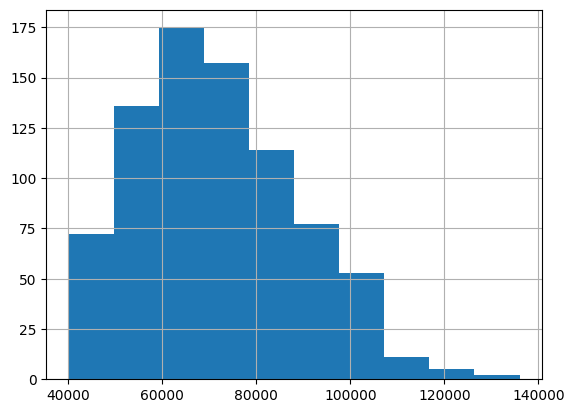

In [ ]:
df.salario.hist()

<Axes: >

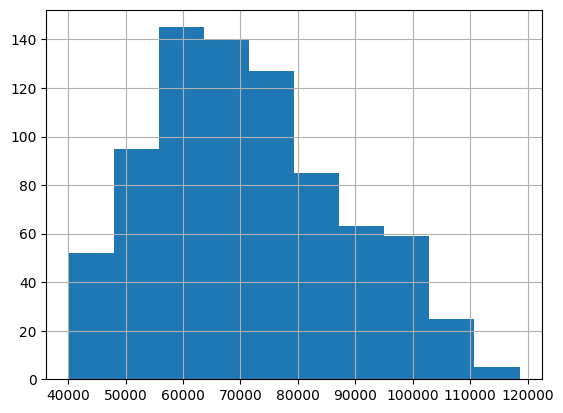

In [ ]:
df_drop.salario.hist()

In [ ]:
len(df)

802

In [ ]:
len(df_drop)

796

<Axes: >

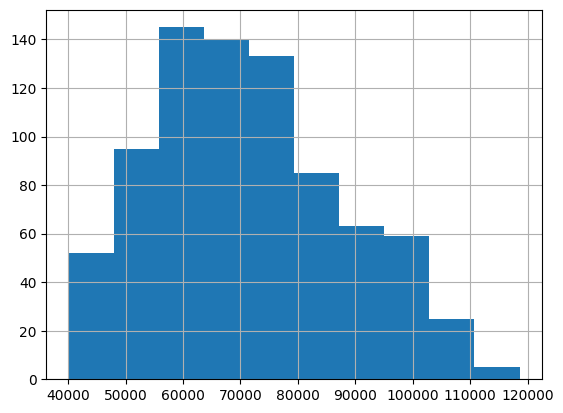

In [ ]:
df_mean.salario.hist()

<Axes: >

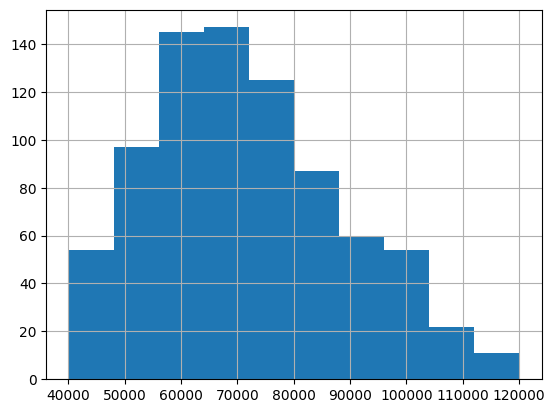

In [ ]:
df_win.salario.hist()

<Axes: >

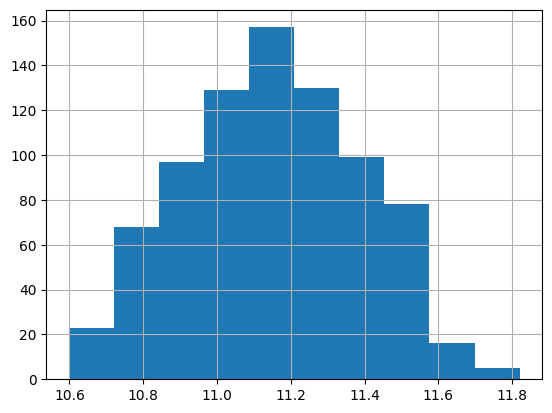

In [ ]:
np.log(df.salario).hist()

TABLAS DE FRECUENCIAS

In [ ]:
df.departamento.value_counts()

,count
departamento,
Development,203
Production,186
Sales,130
Customer Service,61
Research,51
Quality Management,48
Human Resources,46
Finance,43
Marketing,34


In [ ]:
freq = df.departamento.value_counts().to_frame().reset_index()
freq.columns = ["Departamento", "Fi"]

In [ ]:
freq

,Departamento,Fi
0,Development,203
1,Production,186
2,Sales,130
3,Customer Service,61
4,Research,51
5,Quality Management,48
6,Human Resources,46
7,Finance,43
8,Marketing,34


In [ ]:

freq["Hi"] = freq["Fi"].cumsum()
freq["fi"] = freq["Fi"]/freq.Fi.sum()
freq["hi"] = freq.fi.cumsum()

In [ ]:
freq

,Departamento,Fi,Hi,fi,hi
0,Development,203,203,0.253117,0.253117
1,Production,186,389,0.231920,0.485037
2,Sales,130,519,0.162095,0.647132
3,Customer Service,61,580,0.076060,0.723192
4,Research,51,631,0.063591,0.786783
5,Quality Management,48,679,0.059850,0.846633
6,Human Resources,46,725,0.057357,0.903990
7,Finance,43,768,0.053616,0.957606
8,Marketing,34,802,0.042394,1.000000


In [ ]:
freq.columns = ["Departamento", "Absoluta", "Absoluta acum", "Relativa", "Relativa acum"]
freq

,Departamento,Absoluta,Absoluta acum,Relativa,Relativa acum
0,Development,203,203,0.253117,0.253117
1,Production,186,389,0.231920,0.485037
2,Sales,130,519,0.162095,0.647132
3,Customer Service,61,580,0.076060,0.723192
4,Research,51,631,0.063591,0.786783
5,Quality Management,48,679,0.059850,0.846633
6,Human Resources,46,725,0.057357,0.903990
7,Finance,43,768,0.053616,0.957606
8,Marketing,34,802,0.042394,1.000000


GRAFICOS

/tmp/ipython-input-3474041080.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("rol").size().plot.pie(autopct='%1.1f%%', explode=(0.1,0,0,0,0,0))


<Axes: >

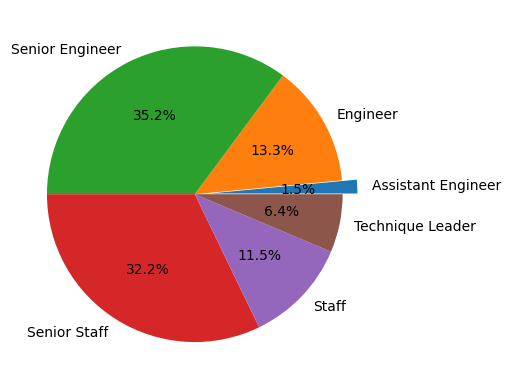

In [ ]:
#Circular

df.groupby("rol").size().plot.pie(autopct='%1.1f%%', explode=(0.1,0,0,0,0,0))

<Axes: xlabel='salario', ylabel='Count'>

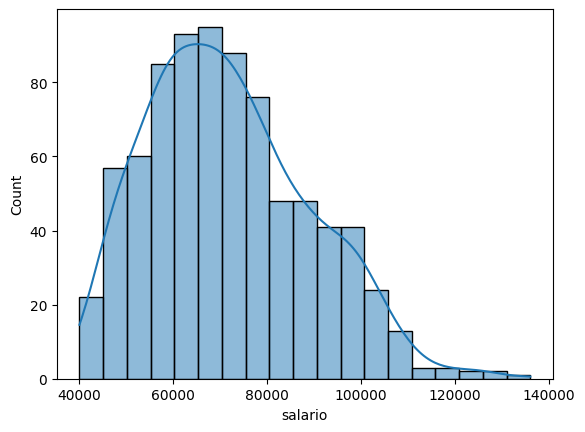

In [ ]:
#HISTOGRAMA Y KDE
sns.histplot(df.salario, kde=True)

<Axes: xlabel='salario', ylabel='Count'>

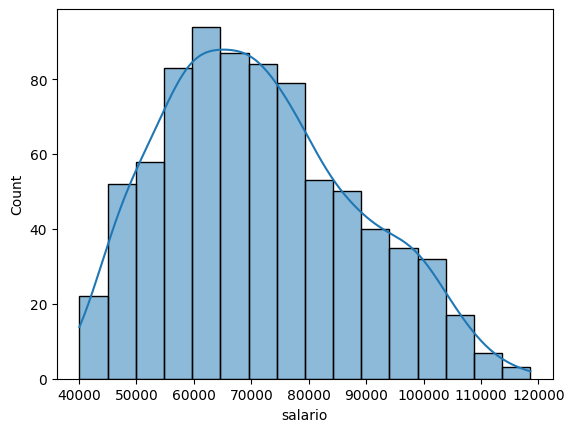

In [ ]:
#HISTOGRAMA Y KDE
sns.histplot(df_drop.salario, kde=True)

CORRELACIÓN

In [ ]:
correlacion = df.select_dtypes(np.number).corr()
correlacion

,emp_no,edad,antiguedad,salario
emp_no,1.000000,-0.021608,0.001839,-0.010524
edad,-0.021608,1.000000,0.001695,-0.029526
antiguedad,0.001839,0.001695,1.000000,0.334078
salario,-0.010524,-0.029526,0.334078,1.000000


<Axes: >

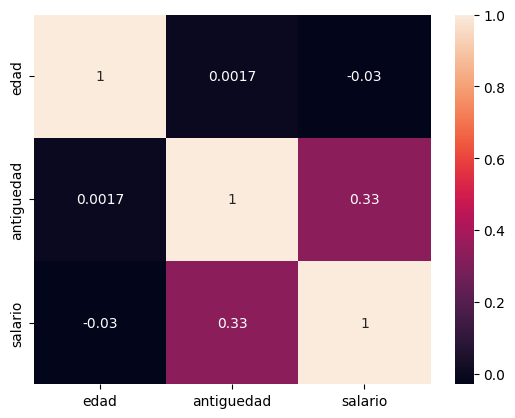

In [ ]:
sns.heatmap(correlacion, annot=True)

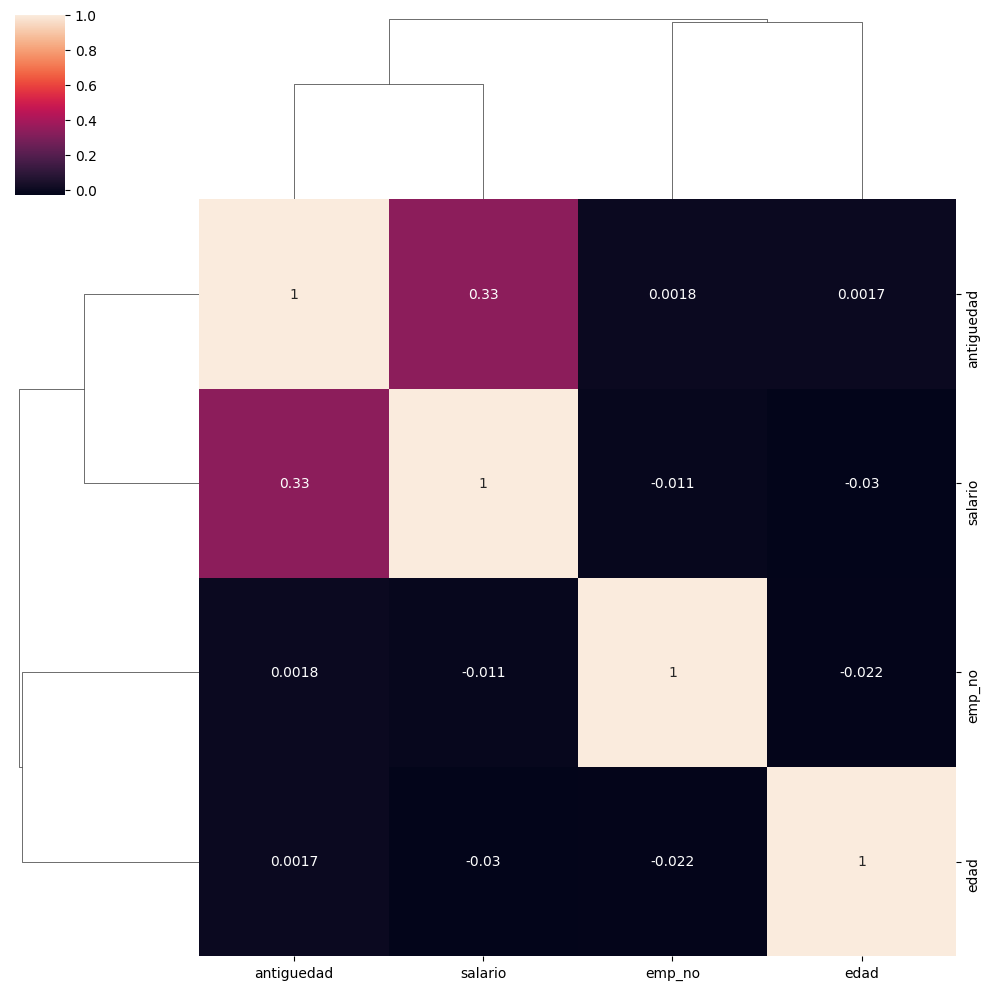

In [ ]:
sns.clustermap(correlacion, annot=True)

OTROS BIVARIANTES

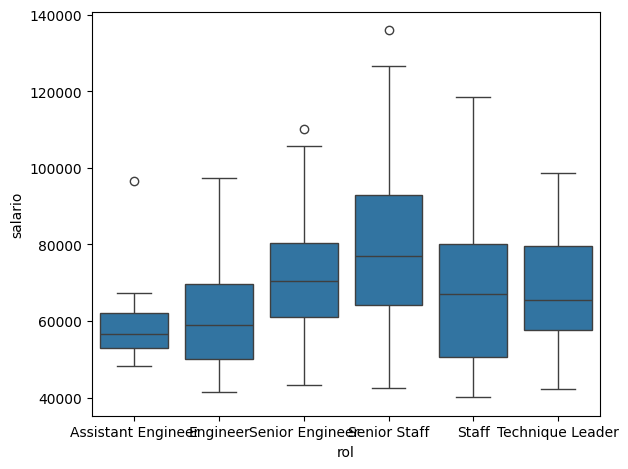

In [ ]:
sns.boxplot(df, x="rol", y="salario")
plt.tight_layout()

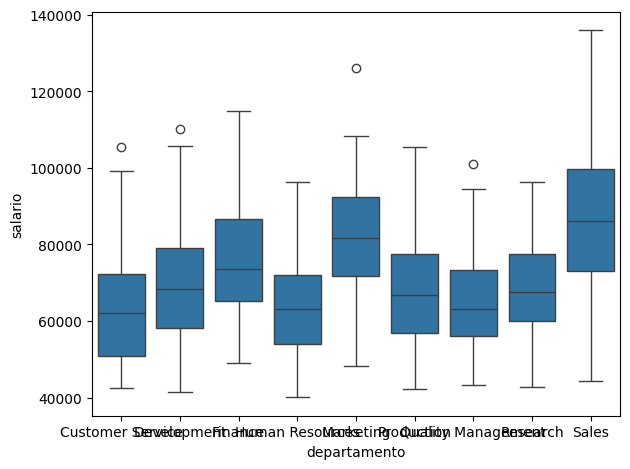

In [ ]:
sns.boxplot(df, x="departamento", y="salario")
plt.tight_layout()

<Axes: xlabel='salario', ylabel='Density'>

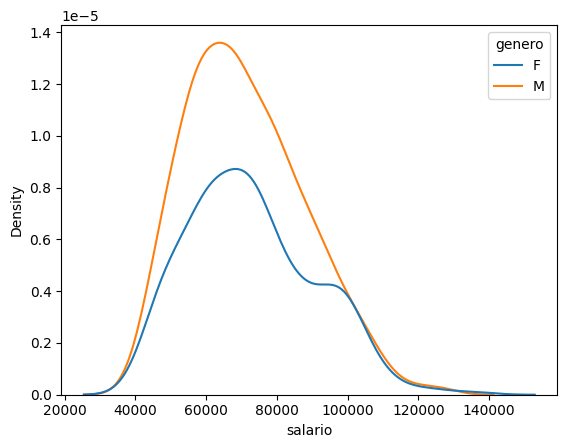

In [ ]:
sns.kdeplot(df, x="salario", hue="genero")

<Axes: xlabel='antiguedad', ylabel='salario'>

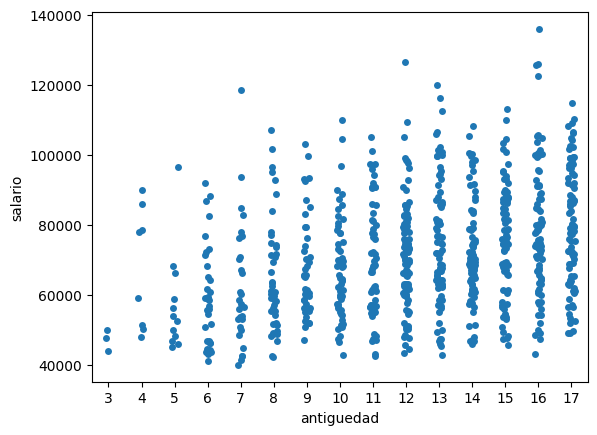

In [ ]:
sns.stripplot(df, x="antiguedad", y="salario")

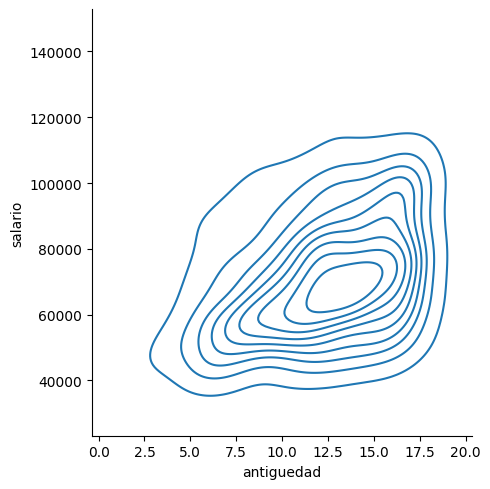

In [ ]:
sns.displot(df, x="antiguedad", y="salario", kind="kde")

TABLAS CONTINGENCIA

In [ ]:
rol_dept = pd.crosstab(df.rol, df.departamento, margins=True)
rol_dept

departamento,Customer Service,Development,Finance,Human Resources,Marketing,Production,Quality Management,Research,Sales,All
rol,,,,,,,,,,
Assistant Engineer,0,4,0,0,0,6,2,0,0,12
Engineer,1,56,0,0,0,40,8,2,0,107
Senior Engineer,7,118,0,0,0,115,31,11,0,282
Senior Staff,38,3,27,35,28,3,0,27,97,258
Staff,15,0,16,11,6,3,0,8,33,92
Technique Leader,0,22,0,0,0,19,7,3,0,51
All,61,203,43,46,34,186,48,51,130,802


In [ ]:
from scipy.stats import chi2_contingency

chi2_contingency(rol_dept)

Chi2ContingencyResult(statistic=np.float64(713.8936074671105), pvalue=np.float64(5.953708946817391e-116), dof=54, expected_freq=array([[9.12718204e-01, 3.03740648e+00, 6.43391521e-01, 6.88279302e-01,
        5.08728180e-01, 2.78304239e+00, 7.18204489e-01, 7.63092269e-01,
        1.94513716e+00, 1.20000000e+01],
       [8.13840399e+00, 2.70835411e+01, 5.73690773e+00, 6.13715711e+00,
        4.53615960e+00, 2.48154613e+01, 6.40399002e+00, 6.80423940e+00,
        1.73441397e+01, 1.07000000e+02],
       [2.14488778e+01, 7.13790524e+01, 1.51197007e+01, 1.61745636e+01,
        1.19551122e+01, 6.54014963e+01, 1.68778055e+01, 1.79326683e+01,
        4.57107232e+01, 2.82000000e+02],
       [1.96234414e+01, 6.53042394e+01, 1.38329177e+01, 1.47980050e+01,
        1.09376559e+01, 5.98354115e+01, 1.54413965e+01, 1.64064838e+01,
        4.18204489e+01, 2.58000000e+02],
       [6.99750623e+00, 2.32867830e+01, 4.93266833e+00, 5.27680798e+00,
        3.90024938e+00, 2.13366584e+01, 5.50623441e+00, 5.85

In [ ]:
chi2_contingency([[1,1,1,1], [1,1,1,1], [1,1,1,1]])

Chi2ContingencyResult(statistic=np.float64(0.0), pvalue=np.float64(1.0), dof=6, expected_freq=array([[1., 1., 1., 1.],
       [1., 1., 1., 1.],
       [1., 1., 1., 1.]]))

In [ ]:
#p_value < 0.05 -> estadisticamente significativo (intervalo confianza 95%)